# 04 · Who should Sales contact first?

Notebook 03 showed where more merchants could come from. This notebook turns that into a **ranked list Sales can work**.

**Flow:** 02 what makes an attractive merchant → 03 where to find more → **04 who to contact first** → 05 how we measure it

**How it works, in four steps:**
1. Work out who Sales should **never** contact (active Snap merchants, hard disqualifications, and a few to verify first).
2. Write each tier as **one filter** on one dataset, for example "website leads not already in Salesforce."
3. Stack the tiers in order and drop the excluded businesses.
4. If a business is in more than one tier, it keeps its **best** (lowest) tier.

| Tier | Play | Who | Why this order |
|---|---|---|---|
| 1 | Inbound | Website leads not already in Salesforce | They asked to talk to us, so speed matters most. Leads that can't be linked (no ZIP) are included and flagged `unlinked`. |
| 2 | Pipeline | Open Salesforce leads that are not `Nurturing` | Deals already in flight are the cheapest to finish. Ranked by TSO. |
| 3 | Pipeline | Salesforce `Nurturing` backlog | A large share of the open TSO, but old. Needs a re-engagement push, ranked by TSO. |
| 4 | Pipeline | Disqualified for a re-engageable reason | Lost for a reason that may no longer apply. Ranked by TSO. |
| 5 | Win-back | Inactive Snap merchants | They know the product, but I don't know *why* they went inactive, so this is a test. |
| 6 | New prospecting | Recently active on cards **and** in the purchased list | Two independent lists agree the business exists and is active. |
| 7 | New prospecting | Recently active on cards only | Active, but size and industry unconfirmed. |
| 8 | New prospecting | Purchased list, proven industry | A lookalike. Size is not a proven filter (see 03). |

The principle: **warm before cold, known intent before inferred fit.**

## Setup

In [ ]:
from pathlib import Path

import duckdb
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

here = Path.cwd().resolve()
repo_root = next(p for p in [here, *here.parents] if (p / "warehouse" / "snap-assessment.duckdb").exists())

# read_only=True so the notebook never blocks `dbt build` from writing to the file.
con = duckdb.connect(str(repo_root / "warehouse" / "snap-assessment.duckdb"), read_only=True)

def q(sql: str) -> pd.DataFrame:
    """Run a SQL query and return the results as a Pandas DataFrame."""
    return con.sql(sql).df()

pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 40)

In [ ]:
# ---- Settings. Change them here and nowhere else. ----

# Same key choice as notebook 03. If you change it there, change it here.
KEY = "strict_key"      # "loose_key" = name + ZIP5, "strict_key" = name + street + ZIP5
KEY_SQL = {
    "loose_key":  "nullif(t.company_name_clean, '') || '|' || t.zip_code_5_digit",
    "strict_key": "nullif(t.company_name_clean, '') || '|' || nullif(t.street_address_clean, '') || '|' || t.zip_code_5_digit",
}[KEY]

RECENT_ACTIVITY = ["Txn within 13 months"]                  # card buckets treated as "recently active"
REENGAGE_REASONS = ["QuikTrak"]                             # disqualified reasons worth another try. QuikTrak looks like a competitor; confirm.
PROVEN_WEB = ["AUTO_SERVICE", "TIRES_RIMS", "JEWELRY", "FURNITURE", "APPLIANCES"]   # website subcategories matching Snap's strong industries (see 02)
PROVEN_SIC_PATTERN = r"automobile repair|automobile body|tire|furniture|jewel|appliance|lubrication"   # purchased SIC labels in those industries
MIN_EMPLOYEES = 0                                           # 03 found size did not separate Snap merchants (n=28), so no filter by default
CAPACITY = 300                                              # placeholder: how many leads Sales can work in a period

## 1. Load each dataset

Each dataset's de-duplicated records, with a `match_key` that identifies the business (the same key as notebook 03). A record with no usable key gets its own `unlinked|...` key, so it stays in the list but never matches anything.

In [ ]:
def src(table: str, id_col: str, cols: list) -> pd.DataFrame:
    """De-duplicated records from a staging table, with a match key and the contact fields Sales needs."""
    extra = (", " + ", ".join(f"t.{c}" for c in cols)) if cols else ""
    df = q(f"""
        select t.{id_col}::varchar as source_id,
               {KEY_SQL} as match_key,
               t.company_name_raw as name, t.street_address_raw as street, t.city_raw as city,
               t.state_raw as state, t.zip_code_raw as zip{extra}
        from "snap-assessment".staging.{table} t
        where t.dupe_record_rank = 1
    """)
    df["linked"] = df["match_key"].notna()
    df["match_key"] = df["match_key"].fillna("unlinked|" + df["source_id"])
    return df

snap = src("stg_snap", "mid", ["is_inactivated"])
card = src("stg_card_list", "merchant_outlet_number", ["last_activity_period"]).drop_duplicates("match_key")
pur  = (src("stg_purchased_list", "speedeonid", ["labels_primary_sic_code_id", "location_employee_count"])
        .rename(columns={"labels_primary_sic_code_id": "sic_label", "location_employee_count": "employees"})
        .sort_values("employees", ascending=False).drop_duplicates("match_key"))
sf   = (src("stg_salesforce_list", "id", ["status", "total_snap_opportunity_tso__c", "age_of_lead__c", "disqualified_reason__c"])
        .rename(columns={"total_snap_opportunity_tso__c": "tso", "age_of_lead__c": "age", "disqualified_reason__c": "reason"}))
web  = (src("stg_website_list", "lead_id", ["form_name", "industry_subcategory"])
        .rename(columns={"form_name": "web_form"}).drop_duplicates("match_key"))

# A few helper columns that make the tier filters below easy to read
snap_active   = snap[~snap["is_inactivated"].astype(bool)]
snap_inactive = snap[snap["is_inactivated"].astype(bool)].drop_duplicates("match_key")

sf["is_open"] = ~sf["status"].isin(["Disqualified", "Converted"])
sf = sf.sort_values(["is_open", "tso"], ascending=False).drop_duplicates("match_key")

card["is_recent"] = card["last_activity_period"].isin(RECENT_ACTIVITY)
card["employees"] = card["match_key"].map(pur.set_index("match_key")["employees"])   # size, when the business is also in the purchased list
pur["sic_proven"] = pur["sic_label"].fillna("").str.contains(PROVEN_SIC_PATTERN, case=False, regex=True)
web["web_fit"] = web["industry_subcategory"].isin(PROVEN_WEB)

{name: len(df) for name, df in [("snap", snap), ("card", card), ("purchased", pur), ("salesforce", sf), ("website", web)]}

{'snap': 1206,
 'card': 1291,
 'purchased': 994,
 'salesforce': 1252,
 'website': 955}

## 2. Who Sales should never contact

Three groups, removed from every tier below:
- **Already an active Snap merchant.**
- **Disqualified in Salesforce** for a reason that is not worth retrying (anything not in `REENGAGE_REASONS`).
- **Salesforce says `Converted`.** I *hold* these instead of contacting them until it is clear what `Converted` means (see 03).

In [ ]:
excluded_keys = {
    "Already an active Snap merchant":
        set(snap_active["match_key"]),
    "Disqualified in Salesforce (not worth retrying)":
        set(sf.loc[(sf["status"] == "Disqualified") & ~sf["reason"].isin(REENGAGE_REASONS), "match_key"]),
    "Salesforce says Converted":
        set(sf.loc[sf["status"] == "Converted", "match_key"]),
}
all_excluded = set().union(*excluded_keys.values())

pd.Series({k: len(v) for k, v in excluded_keys.items()}, name="businesses").to_frame()

,businesses
Already an active Snap merchant,654
Disqualified in Salesforce (not worth retrying),556
Salesforce says Converted,463


## 3. The tiers

Each tier is one line: take one dataset, keep the records that fit, and label them. The order of this list **is** the priority order.

In [ ]:
def tier_list(df, source, tier, label, play, sort_col=None):
    """Label a filtered set of records with its tier. sort_col says how to rank businesses inside the tier (bigger first)."""
    out = df.copy()
    out["source"], out["tier"], out["label"], out["play"] = source, tier, label, play
    out["sort_value"] = out[sort_col].fillna(0).astype(float) if sort_col else 0.0
    return out

sf_keys = set(sf["match_key"])
big_enough = lambda df: df["employees"].fillna(0) >= MIN_EMPLOYEES

tiers = [
    tier_list(web[~web["match_key"].isin(sf_keys)],                               "website",    1, "Inbound website lead, new to Sales",            "Inbound",         "web_fit"),
    tier_list(sf[sf["is_open"] & (sf["status"] != "Nurturing")],                  "salesforce", 2, "Open Salesforce pipeline (in flight)",          "Pipeline",        "tso"),
    tier_list(sf[sf["status"] == "Nurturing"],                                    "salesforce", 3, "Salesforce nurture backlog",                    "Pipeline",        "tso"),
    tier_list(sf[(sf["status"] == "Disqualified") & sf["reason"].isin(REENGAGE_REASONS)],
                                                                                  "salesforce", 4, "Re-engage: disqualified, reason may no longer apply", "Pipeline", "tso"),
    tier_list(snap_inactive,                                                      "snap",       5, "Win-back: inactive Snap merchant",              "Win-back"),
    tier_list(card[card["linked"] & card["is_recent"] & card["match_key"].isin(pur["match_key"]) & big_enough(card)],
                                                                                  "card",       6, "New prospect: active on cards and in purchased list", "New prospecting", "employees"),
    tier_list(card[card["linked"] & card["is_recent"] & big_enough(card)],        "card",       7, "New prospect: active on cards",                 "New prospecting", "employees"),
    tier_list(pur[pur["linked"] & pur["sic_proven"] & big_enough(pur)],           "purchased",  8, "Lookalike: purchased list, proven industry",    "New prospecting", "employees"),
]

## 4. Combine: one row per business, best tier wins

In [ ]:
candidates = pd.concat(tiers, ignore_index=True)
candidates = candidates[~candidates["match_key"].isin(all_excluded)]          # drop the "never contact" businesses

prospects = (candidates
             .sort_values(["tier", "sort_value", "name"], ascending=[True, False, True])
             .drop_duplicates("match_key")                                    # a business in two tiers keeps the lower (better) one
             .reset_index(drop=True))
prospects["priority_rank"] = prospects.index + 1
prospects["match_status"] = np.where(prospects["linked"], "linked", "unlinked")

print(f"{len(prospects):,} businesses on the contact list")

2,542 businesses on the contact list


## 5. What Sales gets

In [ ]:
summary = (prospects.groupby(["tier", "play", "label"])
                    .agg(businesses=("priority_rank", "size"),
                         total_tso=("tso", "sum"),
                         median_age_days=("age", "median"))
                    .reset_index())
summary["pct_of_list"] = (100 * summary["businesses"] / summary["businesses"].sum()).round(1)
summary["cumulative_businesses"] = summary["businesses"].cumsum()
summary["total_tso"] = summary["total_tso"].round(0)
summary

,tier,play,label,businesses,total_tso,median_age_days,pct_of_list,cumulative_businesses
0,1,Inbound,"Inbound website lead, new to Sales",475,0.0,NaN,18.7,475
1,2,Pipeline,Open Salesforce pipeline (in flight),16,463688.0,117.0,0.6,491
2,3,Pipeline,Salesforce nurture backlog,171,2608923.0,656.0,6.7,662
3,4,Pipeline,"Re-engage: disqualified, reason may no longer ...",40,0.0,879.0,1.6,702
4,5,Win-back,Win-back: inactive Snap merchant,506,0.0,NaN,19.9,1208
5,6,New prospecting,New prospect: active on cards and in purchased...,122,0.0,NaN,4.8,1330
6,7,New prospecting,New prospect: active on cards,698,0.0,NaN,27.5,2028
7,8,New prospecting,"Lookalike: purchased list, proven industry",514,0.0,NaN,20.2,2542


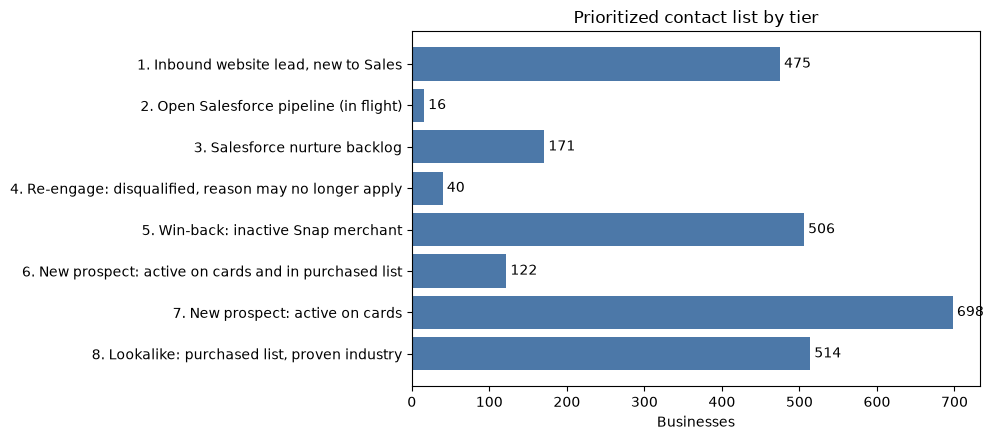

In [ ]:
fig, ax = plt.subplots(figsize=(10, 4.5))
plot = summary.iloc[::-1]
ax.barh([f"{t}. {l}" for t, l in zip(plot["tier"], plot["label"])], plot["businesses"], color="#4C78A8")
for y, v in enumerate(plot["businesses"]):
    ax.text(v, y, f" {v:,}", va="center")
ax.set_xlabel("Businesses")
ax.set_title("Prioritized contact list by tier")
plt.tight_layout()
plt.show()

**Who is *not* on the list, and why:**

In [ ]:
listed = set(prospects["match_key"])
linked_card_pur = set(card.loc[card["linked"], "match_key"]) | set(pur.loc[pur["linked"], "match_key"])

not_listed = {k: len(v) for k, v in excluded_keys.items()}
not_listed["Card or purchased, no usable name/ZIP to verify"] = int((~card["linked"]).sum() + (~pur["linked"]).sum())
not_listed["Card or purchased, but no strong signal (not recent, not a proven industry)"] = len(linked_card_pur - listed - all_excluded)
pd.Series(not_listed, name="businesses").to_frame()

,businesses
Already an active Snap merchant,654
Disqualified in Salesforce (not worth retrying),556
Salesforce says Converted,463
"Card or purchased, no usable name/ZIP to verify",0
"Card or purchased, but no strong signal (not recent, not a proven industry)",410


**The first few of each tier**, to check that the ordering makes sense to a human:

In [ ]:
prospects.groupby("tier").head(3)[["priority_rank", "tier", "name", "city", "zip", "status", "tso", "age", "employees", "match_status"]]

,priority_rank,tier,name,city,zip,status,tso,age,employees,match_status
0,1,1,2120851-dcwp,Brooklyn,88792,NaN,NaN,NaN,<NA>,linked
1,2,1,413 wholesale,Las Vegas,10896,NaN,NaN,NaN,<NA>,linked
2,3,1,465 truck and trailer repair inc,Indianapolis,53796,NaN,NaN,NaN,<NA>,linked
475,476,2,7 One 3 Tire and Wheel Center,Houston,22915,Merchant Invitation Sent,212538.890625,223.0,<NA>,linked
476,477,2,Rainwater's Transmission,Springtown,23917,Merchant Invitation Sent,150050.093750,29.0,<NA>,linked
477,478,2,Dallas Car Stereo Bruton,Dallas,24782,Merchant Invitation Sent,52404.488281,535.0,<NA>,linked
491,492,3,Abilene Parts Plus -,Abilene,20396,Nurturing,350042.781250,569.0,<NA>,linked
492,493,3,Fisher Jewelry Odessa,Odessa,20238,Nurturing,299998.281250,602.0,<NA>,linked
493,494,3,Pollys fine jewelers,North Charleston,70593,Nurturing,299919.312500,1149.0,<NA>,linked
662,663,4,"Advantage Air Heating & Cooling, llc",Danville,56985,Disqualified,NaN,929.0,<NA>,linked


## 6. Sanity checks

In [ ]:
assert prospects["match_key"].is_unique, "a business appears twice"
assert prospects["priority_rank"].is_unique
assert not prospects["match_key"].isin(set(snap_active["match_key"])).any(), "an active Snap merchant is on the list"
assert set(prospects["tier"]) <= set(range(1, 9))
print("All checks passed")

All checks passed


**One more check: the same business under two keys.** If the key is strict, one business with two street spellings becomes two records. It could then be on the list *and* excluded, or on the list twice. Count how often that happens.

## 7. Hand-off: the list for Sales

In [ ]:
OUT_COLS = ["priority_rank", "tier", "play", "label", "source", "name", "street", "city", "state", "zip",
            "status", "tso", "age", "reason", "last_activity_period", "employees", "sic_label", "industry_subcategory",
            "web_form", "match_status"]

out_dir = repo_root / "data" / "outputs"          # data/ is git-ignored, so the list stays out of the repo
out_dir.mkdir(parents=True, exist_ok=True)
prospects[OUT_COLS].to_csv(out_dir / "prioritized_prospects.csv", index=False)
print(f"Wrote {len(prospects):,} rows to {out_dir / 'prioritized_prospects.csv'}")

prospects[OUT_COLS].head(10)

Wrote 2,542 rows to C:\dev\snap-assessment\data\outputs\prioritized_prospects.csv


,priority_rank,tier,play,label,source,name,street,city,state,zip,status,tso,age,reason,last_activity_period,employees,sic_label,industry_subcategory,web_form,match_status
0,1,1,Inbound,"Inbound website lead, new to Sales",website,2120851-dcwp,"7231 Atlantic Ave, Brooklyn NY 88792",Brooklyn,ME,88792,NaN,NaN,NaN,NaN,NaN,<NA>,NaN,TIRES_RIMS,LONG_FORM,linked
1,2,1,Inbound,"Inbound website lead, new to Sales",website,413 wholesale,"6439 Polaris Ave Ste 75, Las Vegas NV 10896",Las Vegas,MN,10896,NaN,NaN,NaN,NaN,NaN,<NA>,NaN,FURNITURE,LONG_FORM,linked
2,3,1,Inbound,"Inbound website lead, new to Sales",website,465 truck and trailer repair inc,"6879 S Arlington Ave, Indianapolis IN 53796",Indianapolis,OR,53796,NaN,NaN,NaN,NaN,NaN,<NA>,NaN,AUTO_SERVICE,LONG_FORM,linked
3,4,1,Inbound,"Inbound website lead, new to Sales",website,5 R Tire and Services,7986 W US Highway 20,Buffalo,DE,24168,NaN,NaN,NaN,NaN,NaN,<NA>,NaN,TIRES_RIMS,LONG_FORM,linked
4,5,1,Inbound,"Inbound website lead, new to Sales",website,A Plus Transmission - Willowbrook,5185 Cypress Creek Parkway,Houston,DE,22930,NaN,NaN,NaN,NaN,NaN,<NA>,NaN,AUTO_SERVICE,LONG_FORM,linked
5,6,1,Inbound,"Inbound website lead, new to Sales",website,"A&S AUTO SALES & REPAIR, LLC","7598 Little York Rd, Houston TX 22906",Houston,DE,22906,NaN,NaN,NaN,NaN,NaN,<NA>,NaN,AUTO_SERVICE,LONG_FORM,linked
6,7,1,Inbound,"Inbound website lead, new to Sales",website,A&V General Merchandise and More,7896 Luau St,Mesquite,DE,24849,NaN,NaN,NaN,NaN,NaN,<NA>,NaN,APPLIANCES,LONG_FORM,linked
7,8,1,Inbound,"Inbound website lead, new to Sales",website,AAMCO,"6923 Wall Ave, Ogden UT 15598",Ogden,CT,15598,NaN,NaN,NaN,NaN,NaN,<NA>,NaN,AUTO_SERVICE,LONG_FORM,linked
8,9,1,Inbound,"Inbound website lead, new to Sales",website,AAMCO,"7679 W Pioneer Pkwy, Pantego TX 23986",Pantego,DE,23986,NaN,NaN,NaN,NaN,NaN,<NA>,NaN,AUTO_SERVICE,LONG_FORM,linked
9,10,1,Inbound,"Inbound website lead, new to Sales",website,AJs Automotive LLC,"436 County Road 487, Corinth MS 61165",Corinth,NE,61165,NaN,NaN,NaN,NaN,NaN,<NA>,NaN,AUTO_SERVICE,LONG_FORM,linked


## Assumptions

**Judgment calls I made** (all easy to change in the settings cell):
- Warm before cold: inbound and existing pipeline come before any purchased or card-only prospect.
- Disqualified leads are excluded unless the reason is in `REENGAGE_REASONS`.
- `Converted` leads not found in Snap are **held, not contacted**, until the meaning of `Converted` is confirmed.
- Inactive Snap merchants are a win-back test, since I don't know why they went inactive.
- No size filter by default, because the size test in 03 had only 28 matches.

**Limits**
- Exact matching means one business can appear as two records under two spellings. The clash check in section 6 counts how often. Changing `KEY` changes the cold tiers (6 to 8) the most.
- The ordering inside tiers 6 to 8 is weak. It uses employee count, which the data doesn't show predicts success.
- Nothing here has outcome data. The tiers are hypotheses, and notebook 05 describes how to test them.

**In production** this becomes a dbt mart (`mart_prospects`), refreshed when the sources refresh, with the tier rules as tested SQL.

## Takeaways

**Bottom line:** The contact list has 2,542 businesses, but only about 28% of it is warm. Sales's live pipeline is small (16 deals in flight), so most of the near-term value is in leads that have already been touched once: new inbound leads and a large, old nurture backlog.

### How the list breaks down
| Play | Tiers | Businesses | Share |
|---|---|---|---|
| Warm: inbound and existing pipeline | 1 to 4 | 702 | 28% |
| Win-back: inactive Snap merchants | 5 | 506 | 20% |
| New prospecting: card and purchased lists | 6 to 8 | 1,334 | 52% |

- **Inbound (tier 1):** 475 website leads that are not already in Salesforce. These asked to talk to us, so they go first.
- **Pipeline (tiers 2 to 4):** only 16 deals are in flight (about $464K TSO). The `Nurturing` backlog is 171 leads carrying about $2.6M of TSO, with a median age of 656 days. The highest-value nurture leads are $300K+ each and 570+ days old. Another 40 leads were disqualified for a reason that may no longer apply.
- **Win-back (tier 5):** 506 inactive Snap merchants. This is a test, because I don't know why they went inactive.
- **New prospecting (tiers 6 to 8):** 122 businesses are active on cards **and** in the purchased list (the strongest cold signal). Another 698 are card-active only, and 514 are purchased-list lookalikes in industries Snap already serves.

### What Sales does Monday morning
1. Call the inbound leads in tier 1, starting with the industries that fit Snap's strongest segments.
2. Finish the 16 in-flight deals, then run a re-engagement push on the nurture backlog, highest TSO first.
3. Only then work cold prospects, starting with the 122 that appear on both the card and purchased lists.

### What I'm least sure about
- **The cold tiers (6 to 8) are the weakest.** They are ordered by employee count, which didn't separate good Snap merchants in notebook 03, and the card-only tier (698) has no industry filter yet.
- **Win-back is an assumption.** No data shows these merchants would return.
- **Converted leads (463) are excluded**, but 81% of them weren't found in Snap. Confirming what `Converted` means could add or remove a large group.
- **Matching is exact**, so some excluded businesses may reappear under another spelling, and the counts are approximate.


In [ ]:
con.close()